In [61]:
from typing import TypedDict
from langgraph.graph import StateGraph,START,END

class State(TypedDict):
    text: str
    is_valid: bool
    output: str
def validate(state:State)->dict:
    return {"is_valid":len(state["text"].strip())>0}
def process(state:State)->dict:
    return {"output":state["text"].upper()}
def fallback(state:State)->dict:
    return{"please enter valid"}
def route_after_validate(state:State)->dict:
    return{ "process" if state["is_valid"] else "fallback"}
builder= StateGraph(State)
builder.add_node("validate",validate)
builder.add_node("process",process)
builder.add_node("route",route_after_validate)
builder.add_node("fallback",fallback)
builder.add_edge(START,"validate")
builder.add_conditional_edges("validate",route_after_validate)
builder.add_edge("process",END)
builder.add_edge("fallback",END)
graph=builder.compile()
result=graph.invoke({"text":"hello"})
print(result)


Task validate with path ('__pregel_pull', 'validate') wrote to unknown channel branch:to:{'process'}, ignoring it.


{'text': 'hello', 'is_valid': True}


In [62]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages=Annotated[list,add_messages]
graph_builder=StateGraph(State)


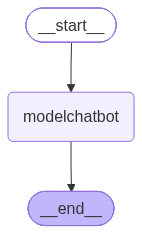

Hello! How can I help you today?


In [63]:
import os
from typing import Annotated
from dotenv import load_dotenv
load_dotenv()
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
model=init_chat_model("groq:openai/gpt-oss-120b", groq_api_key= os.getenv("GROQ_API_KEY"))
class State(TypedDict):
    messages: Annotated[list,add_messages]
def chatbot(state:State):
    return {"messages": [model.invoke(state["messages"])]}
graph_builder=StateGraph(State)
graph_builder.add_node("modelchatbot",chatbot)
graph_builder.add_edge(START,"modelchatbot")
graph_builder.add_edge("modelchatbot",END)
graph=graph_builder.compile()
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass
result=graph.invoke({"messages":"hello"})
print(result["messages"][-1].content)



Chatbot with Tool

In [64]:
import os
from typing import Annotated
from dotenv import load_dotenv
load_dotenv()
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
model=init_chat_model("groq:openai/gpt-oss-120b", groq_api_key= os.getenv("GROQ_API_KEY"))
from langchain_tavily import TavilySearch
tool=TavilySearch(max_results=2)
tool.invoke("what is langgraph explain in one line with less tokens")


{'query': 'what is langgraph explain in one line with less tokens',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://dev.to/garybotlington/i-audited-langgraphs-default-patterns-for-token-efficiency-score-39100-2fc7',
   'title': "I audited LangGraph's default patterns for token efficiency. Score: 39/100. - DEV Community",
   'content': "The pattern: LangGraph's default state is `MessagesState`, which accumulates the full message history and passes it to every node on every call.\n\n`MessagesState`\n`class MessagesState(TypedDict):\nmessages: Annotated[list[AnyMessage], add_messages]`\n\nAfter 5 turns with 2 tool calls each, a node's context window contains:\n\nThe token math for a typical research agent: [...] ## What LangGraph Gets Right\n\nWorth saying clearly: LangGraph is well-designed. The graph abstraction is clean. State management is powerful. The checkpointing architecture is excellent. The streaming support is one of the best in the 

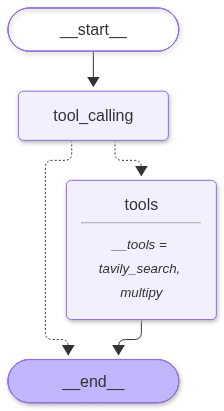

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 billion.\n\nIn the software space, OpenAI announced plans to acquire Pierre Computer Company, which works on code review and repository tools. Meta also announced a deal to acquire coding-agent company Conductor.\n\nOther reported deals include Salesforce's acquisition of Cresta for $2.7 billion, CrowdStrike's reported deals for AI security startups Fiddler AI and Dreadnode, and Dropbox's planned acquisition of Tigris Data for around $350 million. Five9 also agreed to acquire Level AI for approximately $325 million, while Deepgra

In [65]:
def multipy(a:int,b:int)->int:
    """multiple a and b
    Args:
        a(int): first int
        b(int): second int
    Returns:
        int: output int
    """
    return a*b
tools=[tool,multipy]
model_with_tools= model.bind_tools(tools)
#stategraph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from typing import Annotated,TypedDict
#Node definition
class State(TypedDict):
    messages: Annotated[list,add_messages]
def tool_calling(state:State):
    return {"messages":[model_with_tools.invoke(state["messages"])]}
#add nodes
builder=StateGraph(State)
builder.add_node("tool_calling",tool_calling)
builder.add_node("tools",ToolNode(tools))
#add edges
builder.add_edge(START,"tool_calling")
builder.add_conditional_edges("tool_calling",
                # if the latest message (result) from assistant is a tool call-> tools_condition routes to tools
                # if the latest message(result) from assistant is not a tool -> tools_condition routes to END
                              tools_condition)
builder.add_edge("tools",END)
graph=builder.compile()
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass
results=graph.invoke({"messages":"whats the recent ai news"})
print(results["messages"][-1].content)


In [66]:
for m in results['messages']:
    m.pretty_print()



================================ Human Message =================================

whats the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_61c28941-e29d-4ecd-a7fd-02b818d08560)
 Call ID: fc_61c28941-e29d-4ecd-a7fd-02b818d08560
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 billion.\n\nI

In [67]:
results=graph.invoke({"messages":"whats 2 mulitplied by 22 and what is new ceo of nvidia"})
for m in results['messages']:
    m.pretty_print()

================================ Human Message =================================

whats 2 mulitplied by 22 and what is new ceo of nvidia
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3645ceab-5458-409d-a044-816950123b22)
 Call ID: fc_3645ceab-5458-409d-a044-816950123b22
  Args:
    query: new CEO of Nvidia 2026
    search_depth: advanced
    time_range: year
================================= Tool Message =================================
Name: tavily_search

{"query": "new CEO of Nvidia 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://investor.nvidia.com/news/press-release-details/2026/NVIDIA-Announces-CEO-Transition", "title": "NVIDIA Corporation - NVIDIA Announces CEO Transition", "content": "Artificial Intelligence Computing Leadership from NVIDIA\n\n# Press Release Details\n\n### NVIDIA Announces CEO Transition\n\nSANTA CLARA, Calif., Nov. 12, 2026 (GLOBE NEWSWIRE) -- NV

In [ ]:
#React Architeture
def multipy(a:int,b:int)->int:
    """multiple a and b
    Args:
        a(int): first int
        b(int): second int
    Returns:
        int: output int
    """
    return a*b
tools=[tool,multipy]
model_with_tools= model.bind_tools(tools)
#stategraph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from typing import Annotated,TypedDict
#Node definition
class State(TypedDict):
    messages: Annotated[list,add_messages]
def tool_calling(state:State):
    return {"messages":[model_with_tools.invoke(state["messages"])]}
#add nodes
builder=StateGraph(State)
builder.add_node("tool_calling",tool_calling)
builder.add_node("tools",ToolNode(tools))
#add edges
builder.add_edge(START,"tool_calling")
builder.add_conditional_edges("tool_calling",
                # if the latest message (result) from assistant is a tool call-> tools_condition routes to tools
                # if the latest message(result) from assistant is not a tool -> tools_condition routes to END
                              tools_condition)
builder.add_edge("tools","tool_calling")
graph=builder.compile()
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass
results=graph.invoke({"messages":"whats the recent ai news"})
print(results["messages"][-1].content)


ValueError: Found edge ending at unknown node `<function tool_calling at 0x00000242C6891850>`